# Random Variable Generation — Part 1

A computer natively generates only uniform random numbers on $[0,1]$. This notebook builds other distributions from them:

1. **Inverse transform method** — generating the exponential distribution $\mathcal{E}(\lambda)$.
2. **Box–Muller method** — generating Gaussian random variables $\mathcal{N}(\mu, \sigma^2)$.

Each section gives the derivation, followed by a numerical check in Python.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

---
## 1. Inverse transform method

**Notation.** $F_Y(y) = P(Y \le y)$ is the cumulative distribution function (CDF) of $Y$. If $U \sim \mathcal{U}[0,1]$, then $P(U \le a) = a$ for all $a \in [0,1]$.

### 1.1 Principle

Let $U \sim \mathcal{U}[0,1]$ and let $G$ be an increasing bijection. Then $G^{-1}$ exists and is increasing, so applying it preserves inequalities:

$$G(U) \le y \iff U \le G^{-1}(y)$$

Hence

$$P(G(U) \le y) = P\big(U \le G^{-1}(y)\big) = G^{-1}(y),$$

i.e. the CDF of $G(U)$ is $G^{-1}$. Therefore

$$\boxed{Y = G(U) \text{ has CDF } F_Y \iff G = F_Y^{-1}}$$

- $(\Leftarrow)$ if $G = F_Y^{-1}$, then $G^{-1} = F_Y$;
- $(\Rightarrow)$ if $G(U)$ has CDF $F_Y$, then $G^{-1} = F_Y$, so $G = F_Y^{-1}$.

$F_Y$ maps a value to a probability; $F_Y^{-1}$ maps a random probability $U$ back to a value with the desired distribution.

### 1.2 Exponential distribution

For $Y \sim \mathcal{E}(\lambda)$:

$$F^c_Y(y) = P(Y > y) = e^{-\lambda y}, \qquad F_Y(y) = 1 - e^{-\lambda y}, \qquad y \ge 0.$$

Solving $u = F_Y(y)$ for $y$:

$$
\begin{aligned}
u = 1 - e^{-\lambda y}
&\iff e^{-\lambda y} = 1 - u \\
&\iff -\lambda y = \ln(1-u) \\
&\iff y = -\frac{\ln(1-u)}{\lambda}
\end{aligned}
\qquad\Longrightarrow\qquad
\boxed{F_Y^{-1}(u) = -\frac{\ln(1-u)}{\lambda}}
$$

Since $u \in (0,1)$, $\ln(1-u) < 0$ and therefore $y > 0$.

In [2]:
lam = 2
T = 10000

U = np.random.rand(T)
Y = -np.log(1 - U) / lam          # Y = F^{-1}(U)

for y0 in [0.5, 1]:
    print(f"P(Y <= {y0}): empirical = {np.mean(Y <= y0):.4f}   theoretical = {1 - np.exp(-lam*y0):.4f}")

P(Y <= 0.5): empirical = 0.6382   theoretical = 0.6321
P(Y <= 1): empirical = 0.8655   theoretical = 0.8647


The empirical proportions match $F_Y(0.5) \approx 0.632$ and $F_Y(1) \approx 0.865$.

### 1.3 Mean and variance

The density is the derivative of the CDF:

$$f(y) = F_Y'(y) = \lambda e^{-\lambda y}, \quad y \ge 0.$$

**Mean** (integration by parts with $g = y$, $h' = \lambda e^{-\lambda y}$, $h = -e^{-\lambda y}$):

$$
\begin{aligned}
E[Y] &= \int_0^{\infty} y\,\lambda e^{-\lambda y}\,dy
= \Big[-y\,e^{-\lambda y}\Big]_0^{\infty} + \int_0^{\infty} e^{-\lambda y}\,dy \\
&= 0 + \left[-\frac{e^{-\lambda y}}{\lambda}\right]_0^{\infty} = \frac{1}{\lambda}
\end{aligned}
$$

**Second moment** (integration by parts with $g = y^2$):

$$
E[Y^2] = \int_0^{\infty} y^2\,\lambda e^{-\lambda y}\,dy
= \Big[-y^2 e^{-\lambda y}\Big]_0^{\infty} + \int_0^{\infty} 2y\,e^{-\lambda y}\,dy
= \frac{2}{\lambda}\,E[Y] = \frac{2}{\lambda^2}
$$

The boundary terms vanish because $y^n e^{-\lambda y} \to 0$ as $y \to \infty$. Hence

$$\boxed{E[Y] = \frac{1}{\lambda}, \qquad \operatorname{Var}(Y) = E[Y^2] - E[Y]^2 = \frac{1}{\lambda^2}}$$

In [3]:
print(f"Mean:     empirical = {np.mean(Y):.4f}   theoretical = {1/lam}")
print(f"Variance: empirical = {np.var(Y, ddof=1):.4f}   theoretical = {1/lam**2}")
print(f"Standard error of the mean, sigma/sqrt(T) = {(1/lam)/np.sqrt(T):.4f}")

Mean:     empirical = 0.4954   theoretical = 0.5
Variance: empirical = 0.2499   theoretical = 0.25
Standard error of the mean, sigma/sqrt(T) = 0.0050


The deviations from the theoretical values are of the order of $\sigma/\sqrt{T}$, as expected for a finite sample.

### 1.4 Exponential decay on a semi-log scale

Taking the logarithm of the complementary CDF:

$$\ln F^c_Y(y) = -\lambda y.$$

On a semi-log plot, $F^c_Y$ is therefore a straight line with slope $-\lambda$. Between two points $y_1, y_2$:

$$\text{slope} = \frac{\ln F^c(y_2) - \ln F^c(y_1)}{y_2 - y_1} = \frac{-\lambda y_2 + \lambda y_1}{y_2 - y_1} = -\lambda.$$

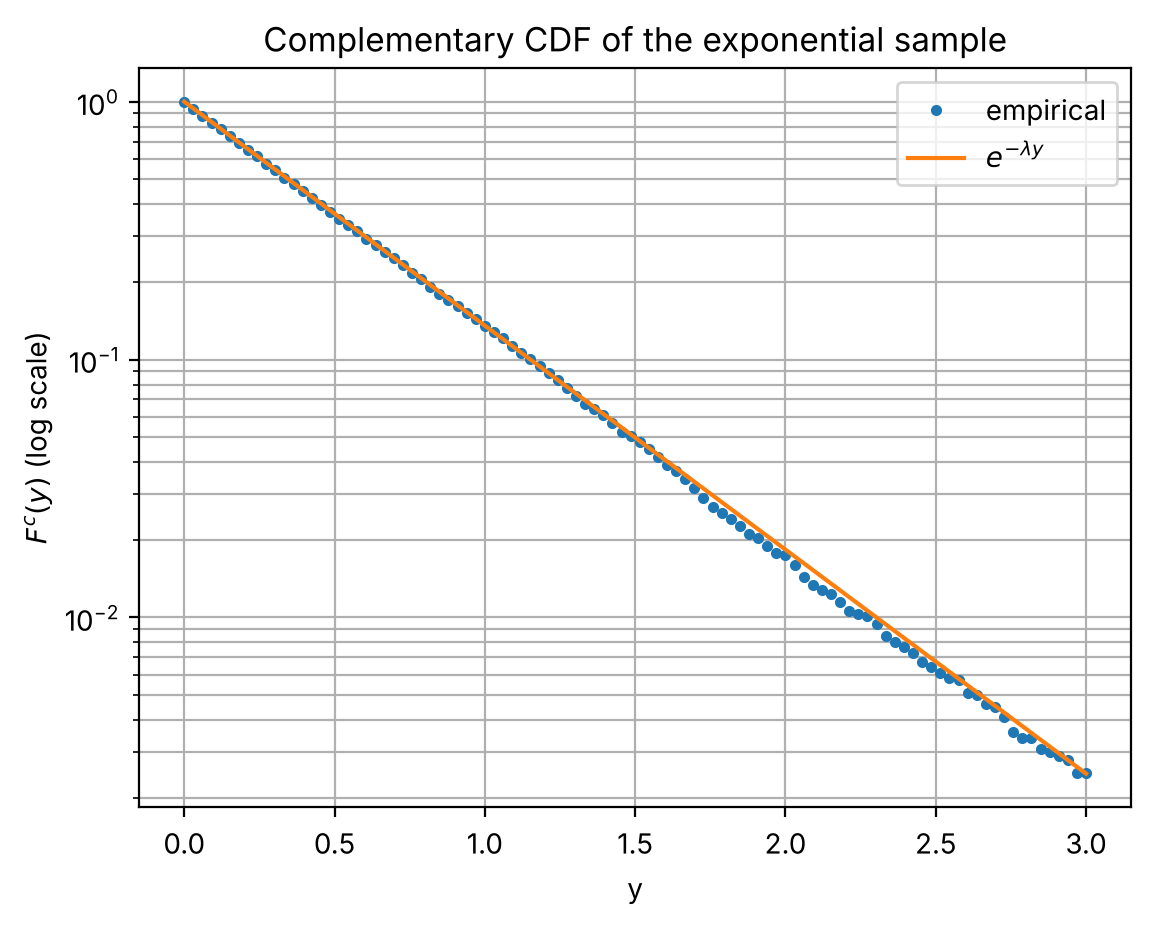

Estimated slope = -1.995   ->   estimated lambda = 1.995   (true lambda = 2)


In [4]:
y_grid = np.linspace(0, 3, 100)
Fc_emp = np.array([np.mean(Y > t) for t in y_grid])
Fc_th = np.exp(-lam * y_grid)

plt.semilogy(y_grid, Fc_emp, "o", markersize=3, label="empirical")
plt.semilogy(y_grid, Fc_th, "-", label=r"$e^{-\lambda y}$")
plt.xlabel("y"); plt.ylabel(r"$F^c(y)$ (log scale)")
plt.title("Complementary CDF of the exponential sample")
plt.legend(); plt.grid(True, which="both")
plt.show()

y1, y2 = 0.5, 1.5
slope = (np.log(np.mean(Y > y2)) - np.log(np.mean(Y > y1))) / (y2 - y1)
print(f"Estimated slope = {slope:.3f}   ->   estimated lambda = {-slope:.3f}   (true lambda = {lam})")

The empirical points lie on a straight line, confirming the exponential decay, and the estimated slope is close to $-\lambda = -2$. For large $y$, few samples exceed $y$ and the estimate becomes noisy, so the slope is measured on $y \le 2$.

---
## 2. Box–Muller method

The Gaussian CDF has no closed-form inverse, so the inverse transform cannot be applied directly. Box–Muller generates **two** independent $\mathcal{N}(0,1)$ variables at once by viewing them as a point $(X_1, X_2)$ of the plane in polar coordinates $x_1 = r\cos\theta$, $x_2 = r\sin\theta$.

### 2.1 $Z = X_1^2 + X_2^2$ follows $\mathcal{E}(1/2)$

Since $X_1, X_2$ are independent, the joint density is the product of the marginal densities:

$$f(x_1, x_2) = \frac{1}{2\pi}\,e^{-(x_1^2 + x_2^2)/2}.$$

It depends only on the distance to the origin, so the point cloud is circularly symmetric. The event $\lbrace Z \ge z\rbrace$ is the exterior of the circle of radius $\sqrt z$:

$$P(Z \ge z) = \iint_{x_1^2 + x_2^2 \ge z} \frac{1}{2\pi}\,e^{-(x_1^2 + x_2^2)/2}\,dx_1\,dx_2.$$

In polar coordinates ($x_1^2 + x_2^2 = r^2$, $dx_1\,dx_2 = r\,dr\,d\theta$, region $r \ge \sqrt z$, $\theta \in [0, 2\pi]$):

$$
P(Z \ge z) = \underbrace{\frac{1}{2\pi}\int_0^{2\pi} d\theta}_{=\,1} \times \int_{\sqrt z}^{\infty} r\,e^{-r^2/2}\,dr
= \Big[-e^{-r^2/2}\Big]_{\sqrt z}^{\infty} = e^{-z/2}.
$$

$$\boxed{P(Z \ge z) = e^{-z/2}} \quad\Longrightarrow\quad Z \sim \mathcal{E}(1/2), \quad E[Z] = 2.$$

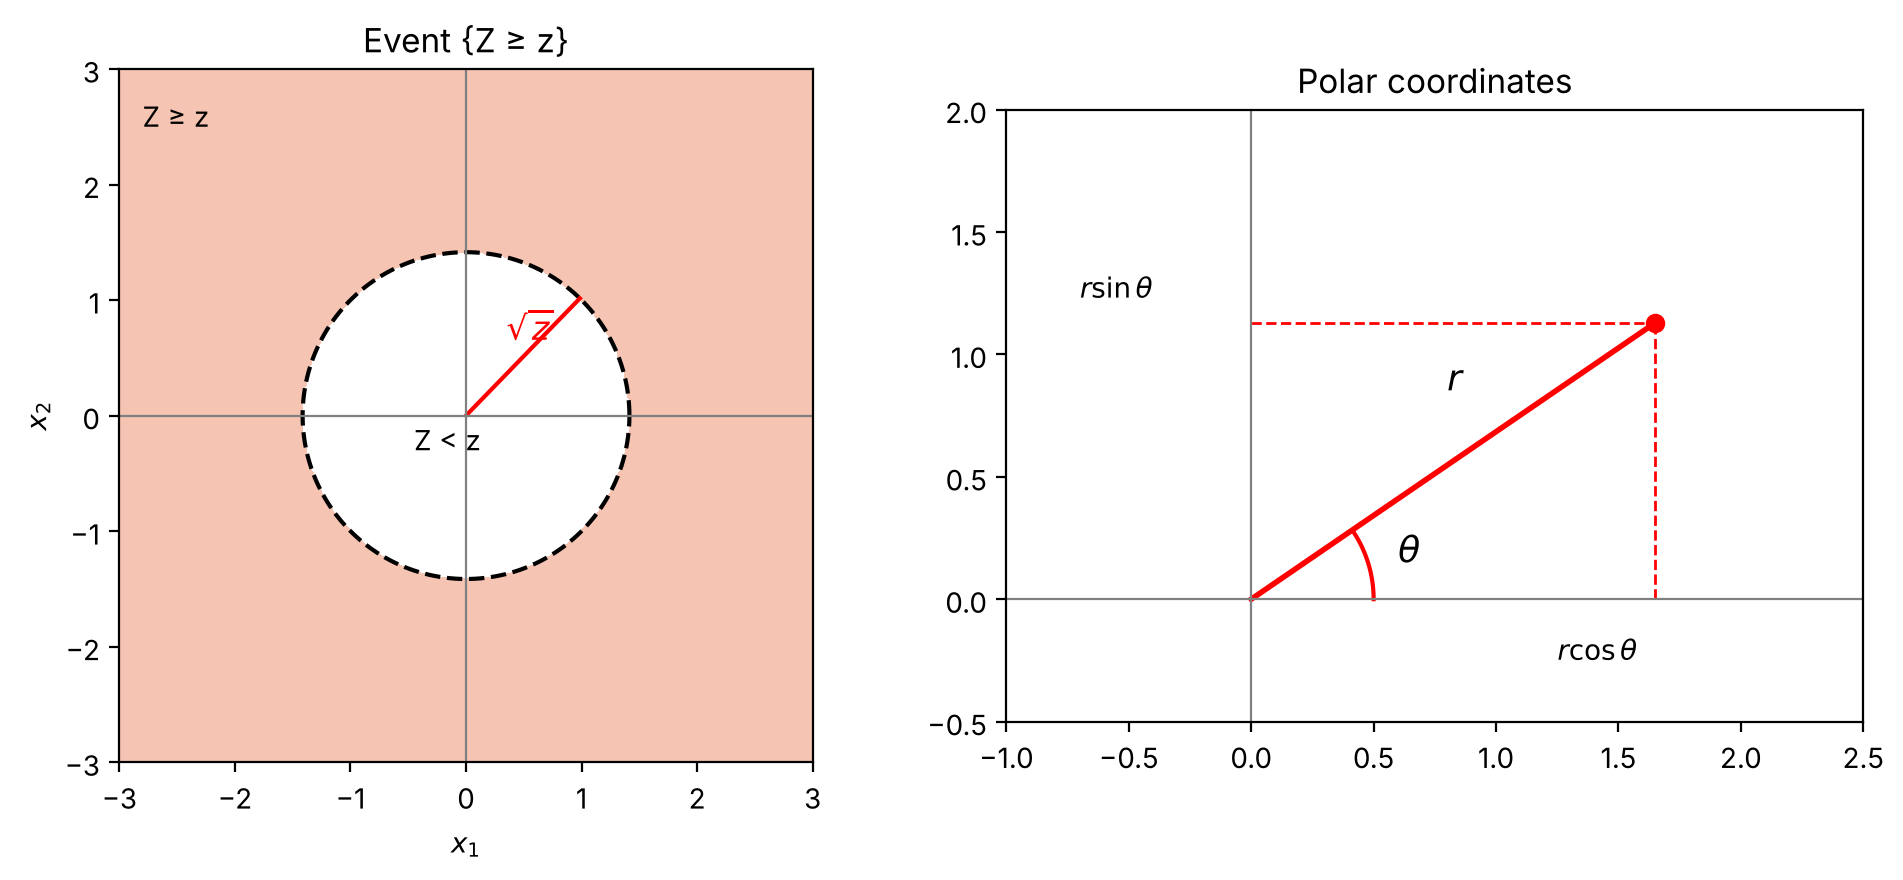

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))

z = 2; R = np.sqrt(z)
xx, yy = np.meshgrid(np.linspace(-3, 3, 400), np.linspace(-3, 3, 400))
ax[0].contourf(xx, yy, (xx**2 + yy**2 >= z).astype(float), levels=[0.5, 1.5], colors=["#f5c4b3"])
t = np.linspace(0, 2*np.pi, 200)
ax[0].plot(R*np.cos(t), R*np.sin(t), "k--")
ax[0].plot([0, R*np.cos(0.8)], [0, R*np.sin(0.8)], "r")
ax[0].text(0.35, 0.65, r"$\sqrt{z}$", color="r", fontsize=12)
ax[0].text(-0.45, -0.3, "Z < z"); ax[0].text(-2.8, 2.5, "Z ≥ z")
ax[0].axhline(0, color="gray", lw=0.8); ax[0].axvline(0, color="gray", lw=0.8)
ax[0].set_aspect("equal"); ax[0].set_title("Event {Z ≥ z}")
ax[0].set_xlabel("$x_1$"); ax[0].set_ylabel("$x_2$")

r, th = 2, 0.6
Mx, My = r*np.cos(th), r*np.sin(th)
ax[1].plot([0, Mx], [0, My], "r", lw=2); ax[1].plot(Mx, My, "ro")
ax[1].plot([Mx, Mx], [0, My], "r--", lw=1); ax[1].plot([0, Mx], [My, My], "r--", lw=1)
tt = np.linspace(0, th, 50); ax[1].plot(0.5*np.cos(tt), 0.5*np.sin(tt), "r")
ax[1].text(0.6, 0.15, r"$\theta$", fontsize=13); ax[1].text(0.8, 0.85, "$r$", fontsize=13)
ax[1].text(Mx-0.4, -0.25, r"$r\cos\theta$"); ax[1].text(-0.7, My+0.1, r"$r\sin\theta$")
ax[1].axhline(0, color="gray", lw=0.8); ax[1].axvline(0, color="gray", lw=0.8)
ax[1].set_xlim(-1, 2.5); ax[1].set_ylim(-0.5, 2); ax[1].set_aspect("equal")
ax[1].set_title("Polar coordinates")
plt.tight_layout(); plt.show()

### 2.2 Distributions of $r^2$ and $\theta$

- $r^2 = X_1^2 + X_2^2 = Z$, hence $r^2 \sim \mathcal{E}(1/2)$.
- In polar coordinates the density $\frac{1}{2\pi}e^{-r^2/2}\,r$ does not depend on $\theta$. For $t \in [0, 2\pi]$:

$$P(\theta \le t) = \frac{1}{2\pi}\int_0^{t} d\theta \times \int_0^{\infty} r\,e^{-r^2/2}\,dr = \frac{t}{2\pi} \times 1 = \frac{t}{2\pi},$$

so $\theta \sim \mathcal{U}[0, 2\pi]$. The density factorizes, so $r$ and $\theta$ are independent.

### 2.3 Algorithm

With $U_1, U_2$ independent $\mathcal{U}[0,1]$:

1. $r = \sqrt{-2\ln(1-U_1)}$ (inverse transform for $r^2 \sim \mathcal{E}(1/2)$);
2. $\theta = 2\pi U_2$;
3. $X_1 = r\cos\theta$, $\quad X_2 = r\sin\theta$.

$X_1$ and $X_2$ are independent $\mathcal{N}(0,1)$ variables.

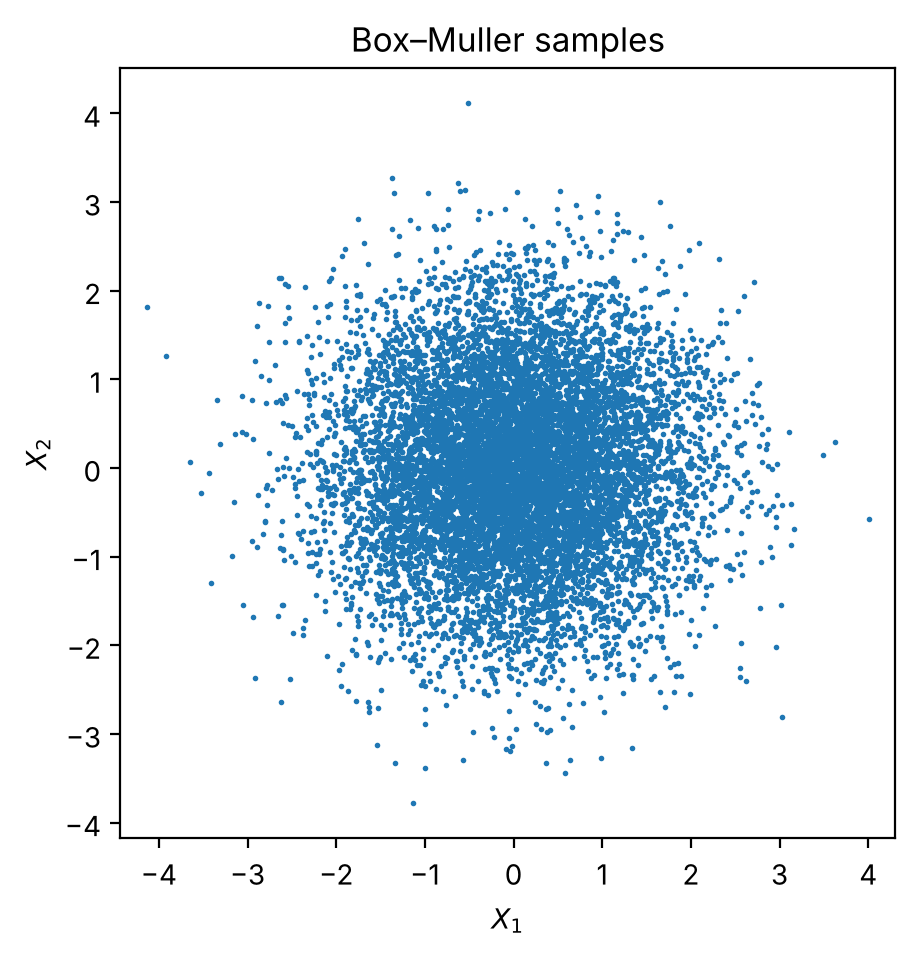

Mean of r^2 = 1.985   (theoretical: 2)
P(Z >= 2): empirical = 0.361   theoretical = 0.368


In [6]:
T = 10000
U1 = np.random.rand(T)
U2 = np.random.rand(T)

r = np.sqrt(-2 * np.log(1 - U1))
theta = 2 * np.pi * U2

X1 = r * np.cos(theta)
X2 = r * np.sin(theta)

plt.figure(figsize=(5, 5))
plt.scatter(X1, X2, s=1)
plt.axis("equal"); plt.xlabel("$X_1$"); plt.ylabel("$X_2$")
plt.title("Box–Muller samples")
plt.show()

print(f"Mean of r^2 = {np.mean(r**2):.3f}   (theoretical: 2)")
print(f"P(Z >= 2): empirical = {np.mean(r**2 >= 2):.3f}   theoretical = {np.exp(-1):.3f}")

The cloud is circularly symmetric and concentrated around the origin, and the statistics of $r^2$ agree with $\mathcal{E}(1/2)$.

### 2.4 From $\mathcal{N}(0,1)$ to $\mathcal{N}(\mu, \sigma^2)$

If $X \sim \mathcal{N}(0,1)$, then

$$\boxed{Y = \mu + \sigma X \sim \mathcal{N}(\mu, \sigma^2)}, \qquad E[Y] = \mu, \quad \operatorname{Var}(Y) = \sigma^2\operatorname{Var}(X) = \sigma^2.$$

For $\mathcal{N}(5, 4)$: $\mu = 5$, $\sigma = \sqrt{4} = 2$.

### 2.5 Verification

Mean:     empirical = 5.0065   theoretical = 5
Variance: empirical = 4.0160   theoretical = 4
P(|Y - mu| <= 1 sigma): empirical = 0.683   theoretical = 0.683
P(|Y - mu| <= 2 sigma): empirical = 0.952   theoretical = 0.954
P(|Y - mu| <= 3 sigma): empirical = 0.998   theoretical = 0.997


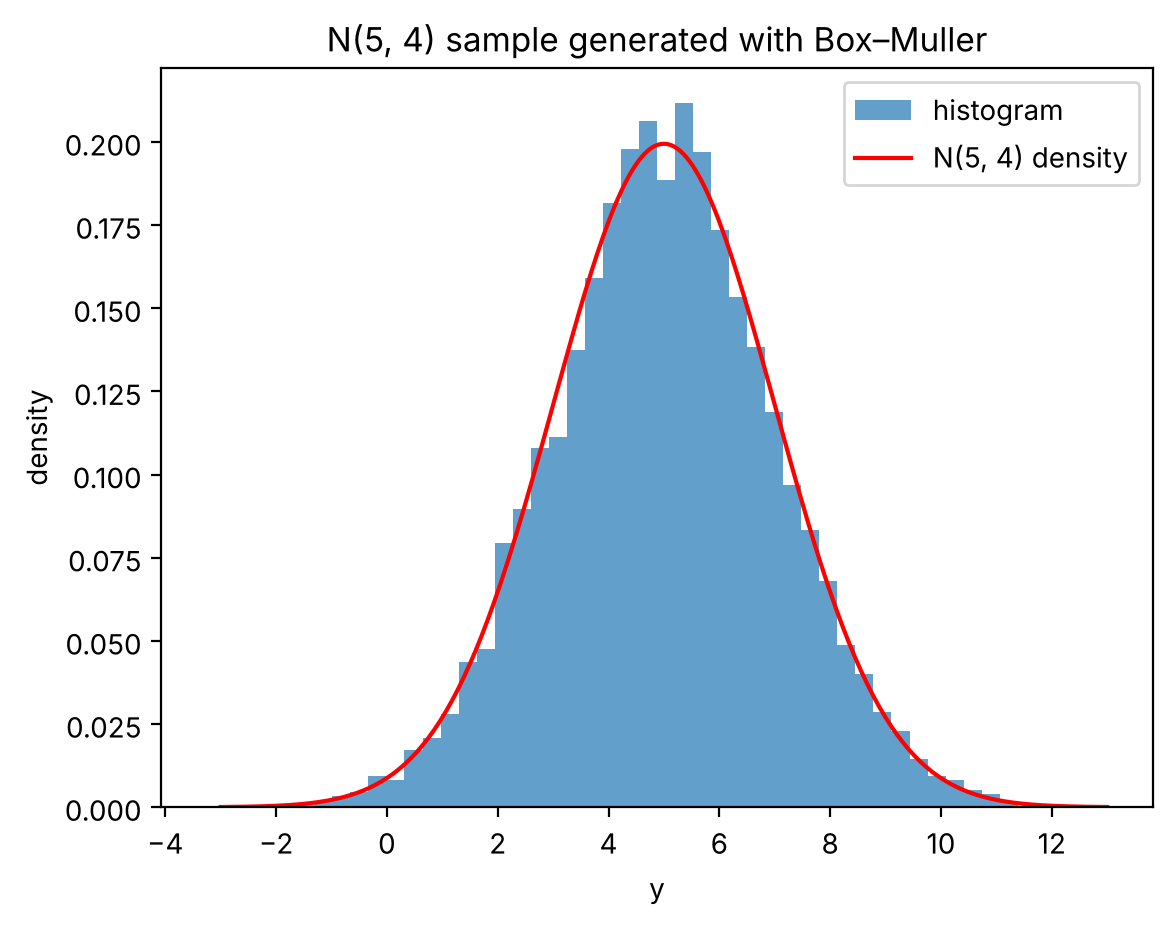

In [7]:
mu, sigma = 5, 2
Yg = mu + sigma * X1

print(f"Mean:     empirical = {np.mean(Yg):.4f}   theoretical = {mu}")
print(f"Variance: empirical = {np.var(Yg, ddof=1):.4f}   theoretical = {sigma**2}")
for k, p in [(1, 0.683), (2, 0.954), (3, 0.997)]:
    print(f"P(|Y - mu| <= {k} sigma): empirical = {np.mean(abs(Yg - mu) <= k*sigma):.3f}   theoretical = {p}")

y = np.linspace(-3, 13, 300)
pdf = np.exp(-(y - mu)**2 / (2*sigma**2)) / (sigma*np.sqrt(2*np.pi))

plt.hist(Yg, bins=50, density=True, alpha=0.7, label="histogram")
plt.plot(y, pdf, "r", label="N(5, 4) density")
plt.xlabel("y"); plt.ylabel("density"); plt.legend()
plt.title("N(5, 4) sample generated with Box–Muller")
plt.show()

The sample mean and variance agree with $\mu = 5$ and $\sigma^2 = 4$, the 68–95–99.7 rule is satisfied, and the histogram follows the theoretical density.

---
## Conclusion

- The **inverse transform method** generates any distribution whose CDF can be inverted in closed form, such as $\mathcal{E}(\lambda)$, in a single line of code.
- The Gaussian CDF cannot be inverted explicitly. **Box–Muller** circumvents this using polar coordinates: the squared radius is exponential (generated by the inverse transform) and the angle is uniform.
- In every case the empirical statistics agree with the theory, with deviations of order $\sigma/\sqrt{T}$.